# Granger analysis across monetary regimes

Tables 3.9–3.18. Original variable order, AIC lag selection, date parser, regimes and VAR-in-levels choices retained. No econometric corrections are introduced. See CODE_MAP.md for the recovered TVL driver.

In [1]:
from pathlib import Path
import os

# Locate the bundle from either its root or the notebooks directory.
_here = Path.cwd().resolve()
_ROOT = next((p for p in [_here, *_here.parents]
              if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if _ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Tesi_codice_consegna folder.")
_DATA_DIR = _ROOT / "data"
_OUTPUT_DIR = _ROOT / "results" / "rerun" / "06_granger_by_regime"
_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(_OUTPUT_DIR)
print("Data:", _DATA_DIR)
print("New outputs:", _OUTPUT_DIR)


Data: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/data
New outputs: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/results/rerun/06_granger_by_regime


## Curve 3pool across regimes

Original analysis retained. Output file labels changed from TVL to Curve to avoid overwriting other analyses; the estimates are unchanged.

Source: `AAVE v2/granger stablecoin CLAUDE.ipynb`, original cell 8 (zero-based).

06_granger_by_regime.ipynb:cell3:274: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
✓ Price adjustment completed


  REGIME: ZIRP (2020-09-01 to 2022-01-31)
✓ Sample size: 396 observations


  VAR ANALYSIS: Curve_ZIRP

Sample period: 2021-01-01 00:00:00 to 2022-01-31 00:00:00
Observations: 396

STATIONARITY CHECKS (for information only)

- Stationarity Test for '3pool':
  ADF Statistic: -7.9963
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for '3m ir':
  ADF Statistic: -6.4021
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'gas_fees':
  ADF Statistic: -5.7028
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'ethperpetual':
  ADF Statistic: -10.4973
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'VIX':
  ADF Statistic: -9.8269
  p-value: 0.0000
  Conclusion: Stationary

- S

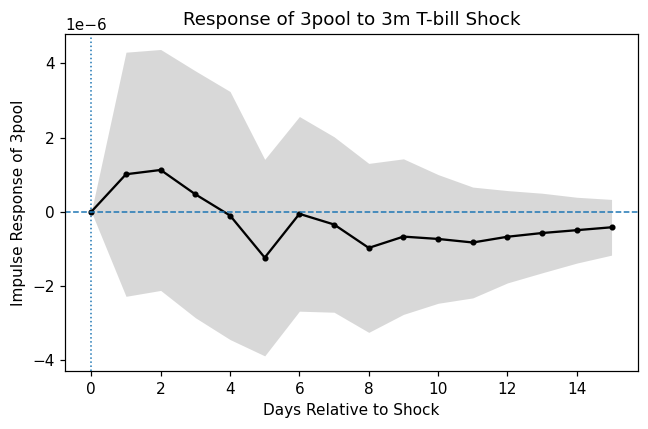

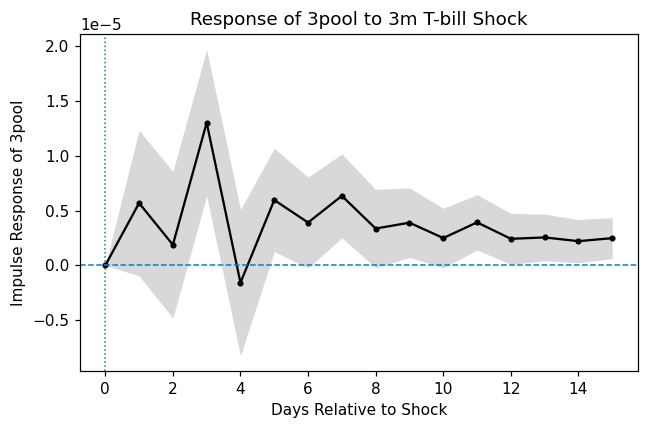

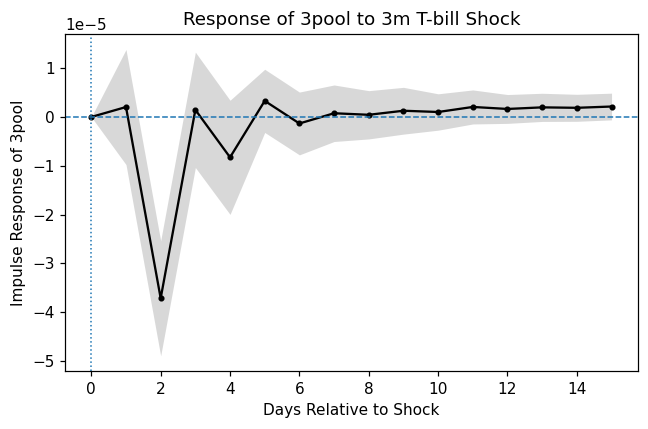

In [2]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from tabulate import tabulate
import matplotlib.pyplot as plt

def check_stationarity(series, name):
    """Performs ADF test for stationarity."""
    print(f"\n- Stationarity Test for '{name}':")
    clean_series = series.dropna()
    
    if len(clean_series) < 10:
        print("  Data too short for ADF test.")
        return False
    
    result = adfuller(clean_series, maxlag=12, autolag='AIC')
    print(f'  ADF Statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    
    is_stationary = result[1] <= 0.05
    print(f"  Conclusion: {'Stationary' if is_stationary else 'Non-stationary (unit root)'}")
    return is_stationary

def prepare_data_for_var(df_analysis):
    """
    Uses levels for VAR estimation following Sims, Stock & Watson (1990).
    
    Rationale: When focus is on forecasting/Granger causality (not structural
    identification), VAR in levels is appropriate even with unit roots.
    Including lags ensures stationary residuals, avoiding spurious regression.
    
    Reference: Sims, C.A., Stock, J.H. & Watson, M.W. (1990). "Inference in 
    Linear Time Series Models with Some Unit Roots." Econometrica, 58(1):113-144.
    """
    # Still check stationarity for reporting purposes
    print("\n" + "="*60)
    print("STATIONARITY CHECKS (for information only)")
    print("="*60)
    
    non_stationary = []
    for col in df_analysis.columns:
        if not check_stationarity(df_analysis[col], col):
            non_stationary.append(col)
    
    print("\n" + "="*60)
    print("VAR SPECIFICATION DECISION")
    print("="*60)
    print(f"\n✓ Using LEVELS for VAR estimation")
    print(f"  Following: Sims, Stock & Watson (1990)")
    print(f"  Rationale: Focus on dynamic relationships (Granger causality)")
    print(f"            not structural identification.")
    print(f"  Note: Including lags ensures residuals are stationary,")
    print(f"        avoiding spurious regression issues.")
    
    if non_stationary:
        print(f"\n  Mixed integration detected: {non_stationary} appear I(1)")
        print(f"  This is acceptable for Granger causality testing in levels.")
    
    return df_analysis.copy(), "levels (Sims et al. 1990)"


def run_var_granger_analysis(df_period, period_name, variables, max_lags=10):
    """Runs complete VAR-Granger causality analysis."""
    print(f"\n\n{'='*60}")
    print(f"  VAR ANALYSIS: {period_name}")
    print(f"{'='*60}")
    
    # --- DATA PREPARATION ---
    missing_vars = [v for v in variables if v not in df_period.columns]
    if missing_vars:
        print(f"❌ Error: Missing columns {missing_vars}")
        return
    
    df_analysis = df_period[variables].dropna()
    
    if len(df_analysis) < 30:
        print(f"❌ Insufficient data: only {len(df_analysis)} observations")
        return
    
    print(f"\nSample period: {df_analysis.index[0]} to {df_analysis.index[-1]}")
    print(f"Observations: {len(df_analysis)}")
    
    # Prepare data (stationarity + cointegration)
    df_stationary, data_type = prepare_data_for_var(df_analysis)
    
    # --- VAR ESTIMATION ---
    print("\n" + "="*60)
    print("  VAR MODEL ESTIMATION")
    print("="*60)
    
    model = VAR(df_stationary)
    
    try:
        results = model.fit(maxlags=max_lags, ic='aic')
        print(f"\n✓ VAR model fitted successfully")
        print(f"  Optimal lag order (AIC): {results.k_ar}")
        print(f"  Data type: {data_type}")
    except Exception as e:
        print(f"❌ Could not fit VAR model: {e}")
        return
    
    # --- GRANGER CAUSALITY TESTS ---
    print("\n" + "="*60)
    print("  GRANGER CAUSALITY TESTS")
    print("="*60)
    
    # Identify target variable
    target_candidates = [col for col in df_stationary.columns 
                        if '3pool' in col.lower() or 
                           'stablecoin' in col.lower() or
                           'tvl' in col.lower()]
    
    if not target_candidates:
        print("❌ Target variable (3pool/stablecoin) not found")
        return
    
    target_var = target_candidates[0]
    causal_vars = [col for col in df_stationary.columns if col != target_var]
    
    print(f"\nTarget (caused): {target_var}")
    print(f"Testing causality from: {causal_vars}")
    
    # Collect results for table
    granger_results = []
    
    # Test each variable individually
    for var in causal_vars:
        print(f"\n--- Testing: {var} → {target_var} ---")
        try:
            test = results.test_causality(caused=target_var, causing=[var], kind='f')
            
            granger_results.append({
                'Causing → Caused': f"{var} → {target_var}",
                'F-stat': f"{test.test_statistic:.3f}",
                'p-value': f"{test.pvalue:.4f}",
                'Result': '***' if test.pvalue < 0.01 else 
                         '**' if test.pvalue < 0.05 else 
                         '*' if test.pvalue < 0.1 else 'No'
            })
            
            print(test.summary())
        except Exception as e:
            print(f"  Error: {e}")
    
    # CRITICAL: Test REVERSE causality
    print(f"\n{'='*60}")
    print("  REVERSE CAUSALITY TEST (Critical for Thesis!)")
    print(f"{'='*60}")
    
    tradfin_vars = [col for col in causal_vars 
                   if '3m' in col.lower() or 'ir' in col.lower() or 'rate' in col.lower()]
    
    if tradfin_vars:
        tradfin_var = tradfin_vars[0]
        print(f"\n--- Testing REVERSE: {target_var} → {tradfin_var} ---")
        
        try:
            reverse_test = results.test_causality(
                caused=tradfin_var,
                causing=[target_var],
                kind='f'
            )
            
            granger_results.append({
                'Causing → Caused': f"{target_var} → {tradfin_var}",
                'F-stat': f"{reverse_test.test_statistic:.3f}",
                'p-value': f"{reverse_test.pvalue:.4f}",
                'Result': '***' if reverse_test.pvalue < 0.01 else 
                         '**' if reverse_test.pvalue < 0.05 else 
                         '*' if reverse_test.pvalue < 0.1 else 'No'
            })
            
            print(reverse_test.summary())
            
            if reverse_test.pvalue > 0.05:
                print(f"\n✓ FINDING: No reverse causality (p={reverse_test.pvalue:.4f})")
                print("  → DeFi is a 'price taker' from TradFi ✓")
            else:
                print(f"\n⚠ WARNING: Reverse causality detected (p={reverse_test.pvalue:.4f})")
                
        except Exception as e:
            print(f"  Error: {e}")
    
    # --- PRINT & SAVE GRANGER TABLE ---
    df_granger = pd.DataFrame(granger_results)
    print("\n" + "="*60)
    print("  GRANGER CAUSALITY SUMMARY TABLE")
    print("="*60)
    print(tabulate(df_granger, headers='keys', tablefmt='grid', showindex=False))
    
    # Save for thesis
    latex_file = f'granger_{period_name.replace(" ", "_")}.tex'
    with open(latex_file, 'w') as f:
        f.write(df_granger.to_latex(index=False, escape=False))
    print(f"\n✓ Saved LaTeX table: {latex_file}")
    
    # --- IMPULSE RESPONSE FUNCTIONS ---
    print("\n" + "="*60)
    print("  IMPULSE RESPONSE FUNCTIONS")
    print("="*60)

    periods = 15
    impulse_var = '3m ir'      # shock TradFi
    response_var = target_var  # '3pool'

    irf = results.irf(periods=periods)

# prendi indici di riga/colonna
    imp_idx = df_stationary.columns.get_loc(impulse_var)
    resp_idx = df_stationary.columns.get_loc(response_var)

# serie IRF e stderr per tutti i periodi (0..periods)
    irf_vals = irf.orth_irfs[:periods+1, resp_idx, imp_idx]
    irf_stderr = irf.stderr(orth=True)[:periods+1, resp_idx, imp_idx]

# intervalli di confidenza 95%
    ci_lower = irf_vals - 1.96 * irf_stderr
    ci_upper = irf_vals + 1.96 * irf_stderr

# asse x = giorni relativi allo shock
    horizon = np.arange(0, periods+1)

    plt.figure(figsize=(6, 4))

# banda grigia CI
    plt.fill_between(
        horizon,
        ci_lower,
        ci_upper,
        color='grey',
        alpha=0.3,
        linewidth=0,
    )

# linea nera con marker
    plt.plot(
        horizon,
        irf_vals,
        color='black',
        marker='.',
        linewidth=1.5,
    )

# linea orizzontale a zero (tratteggiata)
    plt.axhline(0, linestyle='--', linewidth=1)

# linea verticale in T=0 (come FOMC day)
    plt.axvline(0, linestyle=':', linewidth=1)

    plt.xlabel("Days Relative to Shock")
    plt.ylabel("Impulse Response of 3pool")
    plt.title("Response of 3pool to 3m T-bill Shock")

    plt.tight_layout()

    png_file = f'irf_{response_var}_to_{impulse_var}_{period_name.replace(" ", "_")}_clean.png'
    plt.savefig(png_file, dpi=300, bbox_inches='tight')
    print(f"✓ Saved clean IRF plot: {png_file}")
    plt.show()

# =====================================
# MAIN EXECUTION
# =====================================

# =====================================
# MAIN EXECUTION
# =====================================

if __name__ == "__main__":
    try:
        # Load data
        df = pd.read_csv(str(_DATA_DIR / 'aavebtc.csv'), parse_dates=['date'], index_col='date')
        df.sort_index(inplace=True)
        

        
        print(f"✓ Price adjustment completed")
        
        # ============================================================
        # DEFINE PERIODS
        # ============================================================
        periods = {
            'ZIRP': ('2020-09-01', '2022-01-31'),
            'Hike_Cycle': ('2022-03-01', '2023-06-30'),
            'Plateau': ('2023-08-01', '2025-09-11')
        }
        
        # ============================================================
        # DEFINE VARIABLE SETS
        # ============================================================
        VAR_VARIABLES_TVL = [
            '3pool',
            '3m ir',
            'gas_fees',
            'ethperpetual',
            'VIX',
            'volatility_btc'
        ]
        
        # Verify columns exist
        missing = [v for v in VAR_VARIABLES_TVL if v not in df.columns]
        if missing:
            print(f"❌ Missing columns: {missing}")
            print(f"Available columns: {df.columns.tolist()}")
            exit(1)
        
        # ============================================================
        # RUN ANALYSIS FOR EACH PERIOD
        # ============================================================
        for period_name, (start_date, end_date) in periods.items():
            print("\n\n" + "="*80)
            print(f"  REGIME: {period_name} ({start_date} to {end_date})")
            print("="*80)
            
            # Extract period data
            df_period = df[VAR_VARIABLES_TVL].loc[start_date:end_date]
            df_period = df_period.replace([np.inf, -np.inf], np.nan).dropna()
            
            if len(df_period) < 30:
                print(f"⚠ Skipping {period_name}: insufficient data ({len(df_period)} obs)")
                continue
            
            print(f"✓ Sample size: {len(df_period)} observations")
            
            # Run Granger analysis
            run_var_granger_analysis(
                df_period,
                f"Curve_{period_name}",
                VAR_VARIABLES_TVL,
                max_lags=5 if period_name == 'ZIRP' else 5  # puoi cambiare se vuoi
            )
        
    except FileNotFoundError:
        print("❌ Error: str(_DATA_DIR / 'aavebtc.csv') not found")
    except Exception as e:
        print(f"❌ Fatal error: {e}")
        import traceback
        traceback.print_exc()

## Stablecoin lending across regimes

Original analysis retained. Output file labels changed from TVL to Lending only.

Source: `AAVE v2/granger stablecoin CLAUDE.ipynb`, original cell 1 (zero-based).

06_granger_by_regime.ipynb:cell5:274: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
✓ Price adjustment completed


  REGIME: ZIRP (2020-09-01 to 2022-01-31)
✓ Sample size: 396 observations


  VAR ANALYSIS: Lending_ZIRP

Sample period: 2021-01-01 00:00:00 to 2022-01-31 00:00:00
Observations: 396

STATIONARITY CHECKS (for information only)

- Stationarity Test for 'stablecoin':
  ADF Statistic: -8.0391
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for '3m ir':
  ADF Statistic: -6.4021
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'gas_fees':
  ADF Statistic: -5.7028
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'ethperpetual':
  ADF Statistic: -10.4973
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'VIX':
  ADF Statistic: -9.8269
  p-value: 0.0000
  Conclusion: Stationa

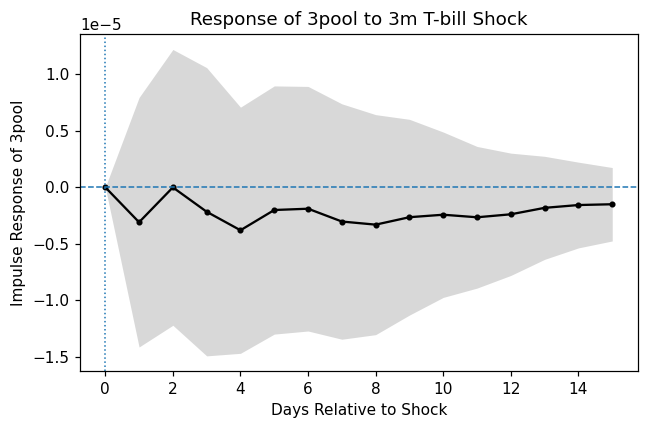

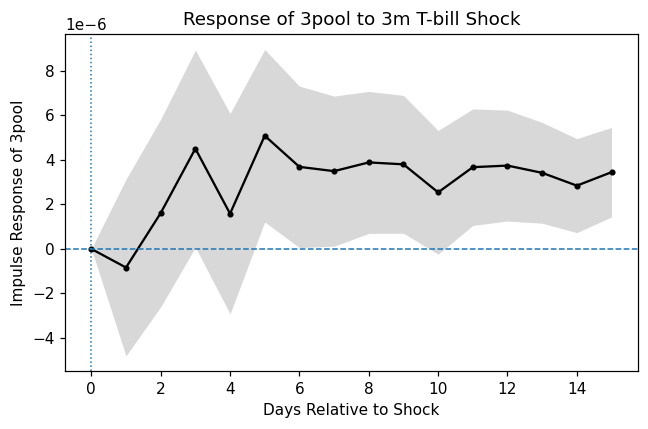

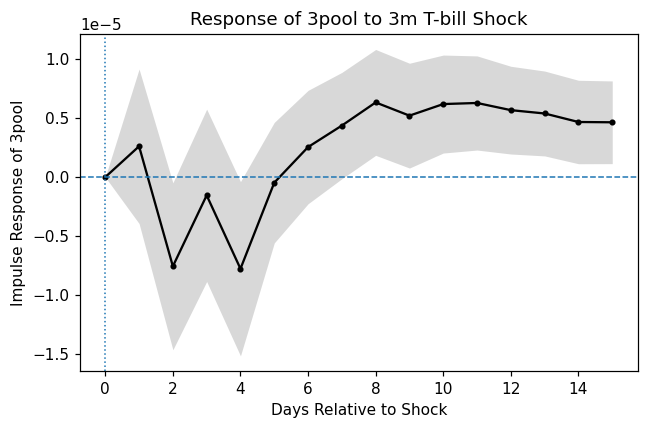

In [3]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from tabulate import tabulate
import matplotlib.pyplot as plt

def check_stationarity(series, name):
    """Performs ADF test for stationarity."""
    print(f"\n- Stationarity Test for '{name}':")
    clean_series = series.dropna()
    
    if len(clean_series) < 10:
        print("  Data too short for ADF test.")
        return False
    
    result = adfuller(clean_series, maxlag=12, autolag='AIC')
    print(f'  ADF Statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    
    is_stationary = result[1] <= 0.05
    print(f"  Conclusion: {'Stationary' if is_stationary else 'Non-stationary (unit root)'}")
    return is_stationary

def prepare_data_for_var(df_analysis):
    """
    Uses levels for VAR estimation following Sims, Stock & Watson (1990).
    
    Rationale: When focus is on forecasting/Granger causality (not structural
    identification), VAR in levels is appropriate even with unit roots.
    Including lags ensures stationary residuals, avoiding spurious regression.
    
    Reference: Sims, C.A., Stock, J.H. & Watson, M.W. (1990). "Inference in 
    Linear Time Series Models with Some Unit Roots." Econometrica, 58(1):113-144.
    """
    # Still check stationarity for reporting purposes
    print("\n" + "="*60)
    print("STATIONARITY CHECKS (for information only)")
    print("="*60)
    
    non_stationary = []
    for col in df_analysis.columns:
        if not check_stationarity(df_analysis[col], col):
            non_stationary.append(col)
    
    print("\n" + "="*60)
    print("VAR SPECIFICATION DECISION")
    print("="*60)
    print(f"\n✓ Using LEVELS for VAR estimation")
    print(f"  Following: Sims, Stock & Watson (1990)")
    print(f"  Rationale: Focus on dynamic relationships (Granger causality)")
    print(f"            not structural identification.")
    print(f"  Note: Including lags ensures residuals are stationary,")
    print(f"        avoiding spurious regression issues.")
    
    if non_stationary:
        print(f"\n  Mixed integration detected: {non_stationary} appear I(1)")
        print(f"  This is acceptable for Granger causality testing in levels.")
    
    return df_analysis.copy(), "levels (Sims et al. 1990)"


def run_var_granger_analysis(df_period, period_name, variables, max_lags=10):
    """Runs complete VAR-Granger causality analysis."""
    print(f"\n\n{'='*60}")
    print(f"  VAR ANALYSIS: {period_name}")
    print(f"{'='*60}")
    
    # --- DATA PREPARATION ---
    missing_vars = [v for v in variables if v not in df_period.columns]
    if missing_vars:
        print(f"❌ Error: Missing columns {missing_vars}")
        return
    
    df_analysis = df_period[variables].dropna()
    
    if len(df_analysis) < 30:
        print(f"❌ Insufficient data: only {len(df_analysis)} observations")
        return
    
    print(f"\nSample period: {df_analysis.index[0]} to {df_analysis.index[-1]}")
    print(f"Observations: {len(df_analysis)}")
    
    # Prepare data (stationarity + cointegration)
    df_stationary, data_type = prepare_data_for_var(df_analysis)
    
    # --- VAR ESTIMATION ---
    print("\n" + "="*60)
    print("  VAR MODEL ESTIMATION")
    print("="*60)
    
    model = VAR(df_stationary)
    
    try:
        results = model.fit(maxlags=max_lags, ic='aic')
        print(f"\n✓ VAR model fitted successfully")
        print(f"  Optimal lag order (AIC): {results.k_ar}")
        print(f"  Data type: {data_type}")
    except Exception as e:
        print(f"❌ Could not fit VAR model: {e}")
        return
    
    # --- GRANGER CAUSALITY TESTS ---
    print("\n" + "="*60)
    print("  GRANGER CAUSALITY TESTS")
    print("="*60)
    
    # Identify target variable
    target_candidates = [col for col in df_stationary.columns 
                        if '3pool' in col.lower() or 
                           'stablecoin' in col.lower() or
                           'tvl' in col.lower()]
    
    if not target_candidates:
        print("❌ Target variable (3pool/stablecoin) not found")
        return
    
    target_var = target_candidates[0]
    causal_vars = [col for col in df_stationary.columns if col != target_var]
    
    print(f"\nTarget (caused): {target_var}")
    print(f"Testing causality from: {causal_vars}")
    
    # Collect results for table
    granger_results = []
    
    # Test each variable individually
    for var in causal_vars:
        print(f"\n--- Testing: {var} → {target_var} ---")
        try:
            test = results.test_causality(caused=target_var, causing=[var], kind='f')
            
            granger_results.append({
                'Causing → Caused': f"{var} → {target_var}",
                'F-stat': f"{test.test_statistic:.3f}",
                'p-value': f"{test.pvalue:.4f}",
                'Result': '***' if test.pvalue < 0.01 else 
                         '**' if test.pvalue < 0.05 else 
                         '*' if test.pvalue < 0.1 else 'No'
            })
            
            print(test.summary())
        except Exception as e:
            print(f"  Error: {e}")
    
    # CRITICAL: Test REVERSE causality
    print(f"\n{'='*60}")
    print("  REVERSE CAUSALITY TEST (Critical for Thesis!)")
    print(f"{'='*60}")
    
    tradfin_vars = [col for col in causal_vars 
                   if '3m' in col.lower() or 'ir' in col.lower() or 'rate' in col.lower()]
    
    if tradfin_vars:
        tradfin_var = tradfin_vars[0]
        print(f"\n--- Testing REVERSE: {target_var} → {tradfin_var} ---")
        
        try:
            reverse_test = results.test_causality(
                caused=tradfin_var,
                causing=[target_var],
                kind='f'
            )
            
            granger_results.append({
                'Causing → Caused': f"{target_var} → {tradfin_var}",
                'F-stat': f"{reverse_test.test_statistic:.3f}",
                'p-value': f"{reverse_test.pvalue:.4f}",
                'Result': '***' if reverse_test.pvalue < 0.01 else 
                         '**' if reverse_test.pvalue < 0.05 else 
                         '*' if reverse_test.pvalue < 0.1 else 'No'
            })
            
            print(reverse_test.summary())
            
            if reverse_test.pvalue > 0.05:
                print(f"\n✓ FINDING: No reverse causality (p={reverse_test.pvalue:.4f})")
                print("  → DeFi is a 'price taker' from TradFi ✓")
            else:
                print(f"\n⚠ WARNING: Reverse causality detected (p={reverse_test.pvalue:.4f})")
                
        except Exception as e:
            print(f"  Error: {e}")
    
    # --- PRINT & SAVE GRANGER TABLE ---
    df_granger = pd.DataFrame(granger_results)
    print("\n" + "="*60)
    print("  GRANGER CAUSALITY SUMMARY TABLE")
    print("="*60)
    print(tabulate(df_granger, headers='keys', tablefmt='grid', showindex=False))
    
    # Save for thesis
    latex_file = f'granger_{period_name.replace(" ", "_")}.tex'
    with open(latex_file, 'w') as f:
        f.write(df_granger.to_latex(index=False, escape=False))
    print(f"\n✓ Saved LaTeX table: {latex_file}")
    
    # --- IMPULSE RESPONSE FUNCTIONS ---
    print("\n" + "="*60)
    print("  IMPULSE RESPONSE FUNCTIONS")
    print("="*60)

    periods = 15
    impulse_var = '3m ir'      # shock TradFi
    response_var = target_var  # '3pool'

    irf = results.irf(periods=periods)

# prendi indici di riga/colonna
    imp_idx = df_stationary.columns.get_loc(impulse_var)
    resp_idx = df_stationary.columns.get_loc(response_var)

# serie IRF e stderr per tutti i periodi (0..periods)
    irf_vals = irf.orth_irfs[:periods+1, resp_idx, imp_idx]
    irf_stderr = irf.stderr(orth=True)[:periods+1, resp_idx, imp_idx]

# intervalli di confidenza 95%
    ci_lower = irf_vals - 1.96 * irf_stderr
    ci_upper = irf_vals + 1.96 * irf_stderr

# asse x = giorni relativi allo shock
    horizon = np.arange(0, periods+1)

    plt.figure(figsize=(6, 4))

# banda grigia CI
    plt.fill_between(
        horizon,
        ci_lower,
        ci_upper,
        color='grey',
        alpha=0.3,
        linewidth=0,
    )

# linea nera con marker
    plt.plot(
        horizon,
        irf_vals,
        color='black',
        marker='.',
        linewidth=1.5,
    )

# linea orizzontale a zero (tratteggiata)
    plt.axhline(0, linestyle='--', linewidth=1)

# linea verticale in T=0 (come FOMC day)
    plt.axvline(0, linestyle=':', linewidth=1)

    plt.xlabel("Days Relative to Shock")
    plt.ylabel("Impulse Response of 3pool")
    plt.title("Response of 3pool to 3m T-bill Shock")

    plt.tight_layout()

    png_file = f'irf_{response_var}_to_{impulse_var}_{period_name.replace(" ", "_")}_clean.png'
    plt.savefig(png_file, dpi=300, bbox_inches='tight')
    print(f"✓ Saved clean IRF plot: {png_file}")
    plt.show()

# =====================================
# MAIN EXECUTION
# =====================================

# =====================================
# MAIN EXECUTION
# =====================================

if __name__ == "__main__":
    try:
        # Load data
        df = pd.read_csv(str(_DATA_DIR / 'aavebtc.csv'), parse_dates=['date'], index_col='date')
        df.sort_index(inplace=True)
        

        
        print(f"✓ Price adjustment completed")
        
        # ============================================================
        # DEFINE PERIODS
        # ============================================================
        periods = {
            'ZIRP': ('2020-09-01', '2022-01-31'),
            'Hike_Cycle': ('2022-03-01', '2023-06-30'),
            'Plateau': ('2023-08-01', '2025-09-11')
        }
        
        # ============================================================
        # DEFINE VARIABLE SETS
        # ============================================================
        VAR_VARIABLES_TVL = [
            'stablecoin',
            '3m ir',
            'gas_fees',
            'ethperpetual',
            'VIX',
            'volatility_btc'
        ]
        
        # Verify columns exist
        missing = [v for v in VAR_VARIABLES_TVL if v not in df.columns]
        if missing:
            print(f"❌ Missing columns: {missing}")
            print(f"Available columns: {df.columns.tolist()}")
            exit(1)
        
        # ============================================================
        # RUN ANALYSIS FOR EACH PERIOD
        # ============================================================
        for period_name, (start_date, end_date) in periods.items():
            print("\n\n" + "="*80)
            print(f"  REGIME: {period_name} ({start_date} to {end_date})")
            print("="*80)
            
            # Extract period data
            df_period = df[VAR_VARIABLES_TVL].loc[start_date:end_date]
            df_period = df_period.replace([np.inf, -np.inf], np.nan).dropna()
            
            if len(df_period) < 30:
                print(f"⚠ Skipping {period_name}: insufficient data ({len(df_period)} obs)")
                continue
            
            print(f"✓ Sample size: {len(df_period)} observations")
            
            # Run Granger analysis
            run_var_granger_analysis(
                df_period,
                f"Lending_{period_name}",
                VAR_VARIABLES_TVL,
                max_lags=5 if period_name == 'ZIRP' else 5  # puoi cambiare se vuoi
            )
        
    except FileNotFoundError:
        print("❌ Error: str(_DATA_DIR / 'aavebtc.csv') not found")
    except Exception as e:
        print(f"❌ Fatal error: {e}")
        import traceback
        traceback.print_exc()

## Price-adjusted TVL across regimes

Original functions, variables and price adjustment retained. The saved source main block runs a full-sample variant, but its saved outputs contain three regimes. The regime loop is recovered from cells 1 and 8 of the same notebook. Treasury-to-TVL F statistics 1.407, 1.463 and 8.223 reproduce the submitted tables.

Source: `AAVE v2/granger stablecoin CLAUDE.ipynb`, original cell 5 (zero-based).

06_granger_by_regime.ipynb:cell7:268: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.


  VAR ANALYSIS: TVL_ZIRP

Sample period: 2021-01-02 00:00:00 to 2022-01-31 00:00:00
Observations: 395

STATIONARITY CHECKS (for information only)

- Stationarity Test for 'tvl_adj%':
  ADF Statistic: -8.0688
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for '3m ir':
  ADF Statistic: -6.3945
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'gas_fees':
  ADF Statistic: -5.7158
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'ethperpetual':
  ADF Statistic: -10.4848
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'VIX':
  ADF Statistic: -9.8050
  p-value: 0.0000
  Conclusion: Stationary

- Stationarity Test for 'volatility_btc':
  ADF Statistic: -4.1884
  p-value: 0.0007
  Conclusion: Stationa

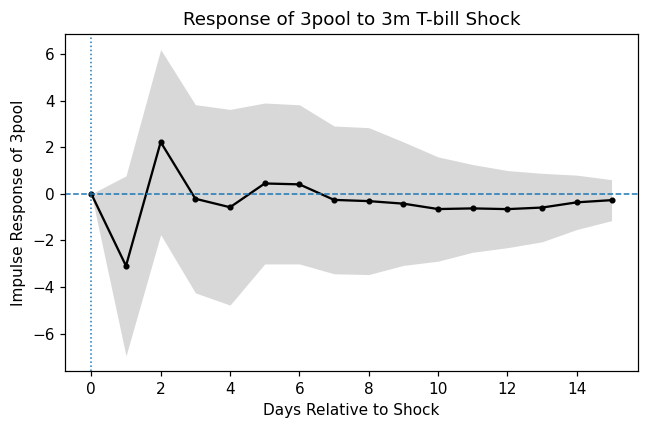

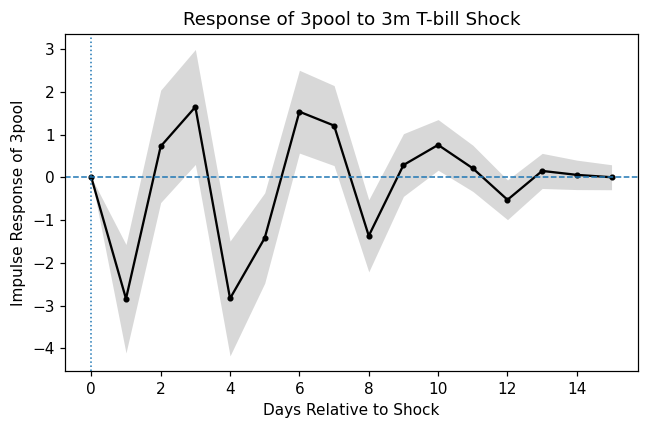

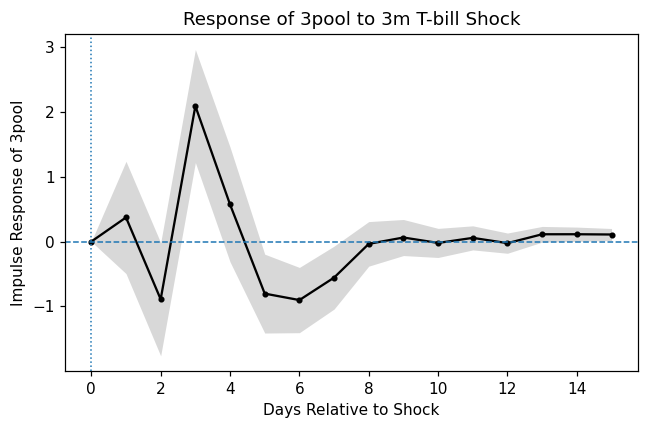

In [4]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from tabulate import tabulate
import matplotlib.pyplot as plt

def check_stationarity(series, name):
    """Performs ADF test for stationarity."""
    print(f"\n- Stationarity Test for '{name}':")
    clean_series = series.dropna()
    
    if len(clean_series) < 10:
        print("  Data too short for ADF test.")
        return False
    
    result = adfuller(clean_series, maxlag=12, autolag='AIC')
    print(f'  ADF Statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    
    is_stationary = result[1] <= 0.05
    print(f"  Conclusion: {'Stationary' if is_stationary else 'Non-stationary (unit root)'}")
    return is_stationary

def prepare_data_for_var(df_analysis):
    """
    Uses levels for VAR estimation following Sims, Stock & Watson (1990).
    
    Rationale: When focus is on forecasting/Granger causality (not structural
    identification), VAR in levels is appropriate even with unit roots.
    Including lags ensures stationary residuals, avoiding spurious regression.
    
    Reference: Sims, C.A., Stock, J.H. & Watson, M.W. (1990). "Inference in 
    Linear Time Series Models with Some Unit Roots." Econometrica, 58(1):113-144.
    """
    # Still check stationarity for reporting purposes
    print("\n" + "="*60)
    print("STATIONARITY CHECKS (for information only)")
    print("="*60)
    
    non_stationary = []
    for col in df_analysis.columns:
        if not check_stationarity(df_analysis[col], col):
            non_stationary.append(col)
    
    print("\n" + "="*60)
    print("VAR SPECIFICATION DECISION")
    print("="*60)
    print(f"\n✓ Using LEVELS for VAR estimation")
    print(f"  Following: Sims, Stock & Watson (1990)")
    print(f"  Rationale: Focus on dynamic relationships (Granger causality)")
    print(f"            not structural identification.")
    print(f"  Note: Including lags ensures residuals are stationary,")
    print(f"        avoiding spurious regression issues.")
    
    if non_stationary:
        print(f"\n  Mixed integration detected: {non_stationary} appear I(1)")
        print(f"  This is acceptable for Granger causality testing in levels.")
    
    return df_analysis.copy(), "levels (Sims et al. 1990)"


def run_var_granger_analysis(df_period, period_name, variables, max_lags=10):
    """Runs complete VAR-Granger causality analysis."""
    print(f"\n\n{'='*60}")
    print(f"  VAR ANALYSIS: {period_name}")
    print(f"{'='*60}")
    
    # --- DATA PREPARATION ---
    missing_vars = [v for v in variables if v not in df_period.columns]
    if missing_vars:
        print(f"❌ Error: Missing columns {missing_vars}")
        return
    
    df_analysis = df_period[variables].dropna()
    
    if len(df_analysis) < 30:
        print(f"❌ Insufficient data: only {len(df_analysis)} observations")
        return
    
    print(f"\nSample period: {df_analysis.index[0]} to {df_analysis.index[-1]}")
    print(f"Observations: {len(df_analysis)}")
    
    # Prepare data (stationarity + cointegration)
    df_stationary, data_type = prepare_data_for_var(df_analysis)
    
    # --- VAR ESTIMATION ---
    print("\n" + "="*60)
    print("  VAR MODEL ESTIMATION")
    print("="*60)
    
    model = VAR(df_stationary)
    
    try:
        results = model.fit(maxlags=max_lags, ic='aic')
        print(f"\n✓ VAR model fitted successfully")
        print(f"  Optimal lag order (AIC): {results.k_ar}")
        print(f"  Data type: {data_type}")
    except Exception as e:
        print(f"❌ Could not fit VAR model: {e}")
        return
    
    # --- GRANGER CAUSALITY TESTS ---
    print("\n" + "="*60)
    print("  GRANGER CAUSALITY TESTS")
    print("="*60)
    
    # Identify target variable
    target_candidates = [col for col in df_stationary.columns 
                        if '3pool' in col.lower() or 
                           'stablecoin' in col.lower() or
                           'tvl' in col.lower()]
    
    if not target_candidates:
        print("❌ Target variable (3pool/stablecoin) not found")
        return
    
    target_var = target_candidates[0]
    causal_vars = [col for col in df_stationary.columns if col != target_var]
    
    print(f"\nTarget (caused): {target_var}")
    print(f"Testing causality from: {causal_vars}")
    
    # Collect results for table
    granger_results = []
    
    # Test each variable individually
    for var in causal_vars:
        print(f"\n--- Testing: {var} → {target_var} ---")
        try:
            test = results.test_causality(caused=target_var, causing=[var], kind='f')
            
            granger_results.append({
                'Causing → Caused': f"{var} → {target_var}",
                'F-stat': f"{test.test_statistic:.3f}",
                'p-value': f"{test.pvalue:.4f}",
                'Result': '***' if test.pvalue < 0.01 else 
                         '**' if test.pvalue < 0.05 else 
                         '*' if test.pvalue < 0.1 else 'No'
            })
            
            print(test.summary())
        except Exception as e:
            print(f"  Error: {e}")
    
    # CRITICAL: Test REVERSE causality
    print(f"\n{'='*60}")
    print("  REVERSE CAUSALITY TEST (Critical for Thesis!)")
    print(f"{'='*60}")
    
    tradfin_vars = [col for col in causal_vars 
                   if '3m' in col.lower() or 'ir' in col.lower() or 'rate' in col.lower()]
    
    if tradfin_vars:
        tradfin_var = tradfin_vars[0]
        print(f"\n--- Testing REVERSE: {target_var} → {tradfin_var} ---")
        
        try:
            reverse_test = results.test_causality(
                caused=tradfin_var,
                causing=[target_var],
                kind='f'
            )
            
            granger_results.append({
                'Causing → Caused': f"{target_var} → {tradfin_var}",
                'F-stat': f"{reverse_test.test_statistic:.3f}",
                'p-value': f"{reverse_test.pvalue:.4f}",
                'Result': '***' if reverse_test.pvalue < 0.01 else 
                         '**' if reverse_test.pvalue < 0.05 else 
                         '*' if reverse_test.pvalue < 0.1 else 'No'
            })
            
            print(reverse_test.summary())
            
            if reverse_test.pvalue > 0.05:
                print(f"\n✓ FINDING: No reverse causality (p={reverse_test.pvalue:.4f})")
                print("  → DeFi is a 'price taker' from TradFi ✓")
            else:
                print(f"\n⚠ WARNING: Reverse causality detected (p={reverse_test.pvalue:.4f})")
                
        except Exception as e:
            print(f"  Error: {e}")
    
    # --- PRINT & SAVE GRANGER TABLE ---
    df_granger = pd.DataFrame(granger_results)
    print("\n" + "="*60)
    print("  GRANGER CAUSALITY SUMMARY TABLE")
    print("="*60)
    print(tabulate(df_granger, headers='keys', tablefmt='grid', showindex=False))
    
    # Save for thesis
    latex_file = f'granger_{period_name.replace(" ", "_")}.tex'
    with open(latex_file, 'w') as f:
        f.write(df_granger.to_latex(index=False, escape=False))
    print(f"\n✓ Saved LaTeX table: {latex_file}")
    
    # --- IMPULSE RESPONSE FUNCTIONS ---
    print("\n" + "="*60)
    print("  IMPULSE RESPONSE FUNCTIONS")
    print("="*60)

    periods = 15
    impulse_var = '3m ir'      # shock TradFi
    response_var = target_var  # '3pool'

    irf = results.irf(periods=periods)

# prendi indici di riga/colonna
    imp_idx = df_stationary.columns.get_loc(impulse_var)
    resp_idx = df_stationary.columns.get_loc(response_var)

# serie IRF e stderr per tutti i periodi (0..periods)
    irf_vals = irf.orth_irfs[:periods+1, resp_idx, imp_idx]
    irf_stderr = irf.stderr(orth=True)[:periods+1, resp_idx, imp_idx]

# intervalli di confidenza 95%
    ci_lower = irf_vals - 1.96 * irf_stderr
    ci_upper = irf_vals + 1.96 * irf_stderr

# asse x = giorni relativi allo shock
    horizon = np.arange(0, periods+1)

    plt.figure(figsize=(6, 4))

# banda grigia CI
    plt.fill_between(
        horizon,
        ci_lower,
        ci_upper,
        color='grey',
        alpha=0.3,
        linewidth=0,
    )

# linea nera con marker
    plt.plot(
        horizon,
        irf_vals,
        color='black',
        marker='.',
        linewidth=1.5,
    )

# linea orizzontale a zero (tratteggiata)
    plt.axhline(0, linestyle='--', linewidth=1)

# linea verticale in T=0 (come FOMC day)
    plt.axvline(0, linestyle=':', linewidth=1)

    plt.xlabel("Days Relative to Shock")
    plt.ylabel("Impulse Response of 3pool")
    plt.title("Response of 3pool to 3m T-bill Shock")

    plt.tight_layout()

    png_file = f'irf_{response_var}_to_{impulse_var}_{period_name.replace(" ", "_")}_clean.png'
    plt.savefig(png_file, dpi=300, bbox_inches='tight')
    print(f"✓ Saved clean IRF plot: {png_file}")
    plt.show()

# =====================================
# MAIN EXECUTION
# =====================================

# Regime driver recovered from cells 1 and 8 of the same source notebook.
df = pd.read_csv(str(_DATA_DIR / 'aavebtc.csv'), parse_dates=['date'], index_col='date')
df.sort_index(inplace=True)
df['eth_price_index'] = (df['eth'] / df['eth'].iloc[0]) * 100
df['tvl_price_adjusted'] = (df['sum of tvl'] / df['eth_price_index']) * 100
df['tvl_adj%'] = df['tvl_price_adjusted'].pct_change() * 100
periods = {
    'ZIRP': ('2020-09-01', '2022-01-31'),
    'Hike_Cycle': ('2022-03-01', '2023-06-30'),
    'Plateau': ('2023-08-01', '2025-09-11'),
}
VAR_VARIABLES_TVL_ADJ = ['tvl_adj%', '3m ir', 'gas_fees', 'ethperpetual', 'VIX', 'volatility_btc']
for period_name, (start_date, end_date) in periods.items():
    df_period = df[VAR_VARIABLES_TVL_ADJ].loc[start_date:end_date]
    df_period = df_period.replace([np.inf, -np.inf], np.nan).dropna()
    run_var_granger_analysis(df_period, f"TVL_{period_name}", VAR_VARIABLES_TVL_ADJ, max_lags=5)
